<b>ML Experiment 6: Implementation of Support Vector Machine (SVM)</b><br><br><b>Aim:</b> Tune Linear, RBF, and Polynomial SVM models using GridSearchCV on Breast Cancer features and visualize non-linear RBF boundaries on concentric moons.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

In [2]:
cancer = load_breast_cancer(as_frame=True)
x_tr, x_te, y_tr, y_te = train_test_split(
    cancer.data, cancer.target, test_size=0.22, stratify=cancer.target, random_state=61
)

svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(random_state=61)),
])

param_grid = {
    "svc__kernel": ["linear", "rbf", "poly"],
    "svc__C": [0.5, 1.0, 5.0],
}

grid = GridSearchCV(svm_pipe, param_grid, cv=5, scoring="accuracy")
grid.fit(x_tr, y_tr)

cv_summary = pd.DataFrame(grid.cv_results_)[
    ["param_svc__kernel", "param_svc__C", "mean_test_score"]
].sort_values("mean_test_score", ascending=False)
print("GridSearchCV Kernel & C Comparison:")
print(cv_summary.head(6).to_string(index=False))

best_svm = grid.best_estimator_

GridSearchCV Kernel & C Comparison:
param_svc__kernel  param_svc__C  mean_test_score
              rbf           5.0         0.972829
              rbf           1.0         0.970557
              rbf           0.5         0.968335
           linear           0.5         0.963764
           linear           1.0         0.961542
           linear           5.0         0.961466


In [3]:
best_preds = best_svm.predict(x_te)
print(f"\nBest Params: {grid.best_params_}")
print(f"Holdout Accuracy: {accuracy_score(y_te, best_preds):.4f} | F1: {f1_score(y_te, best_preds):.4f}")
print("\nClassification Report:")
print(classification_report(y_te, best_preds, target_names=cancer.target_names))

xm, ym = make_moons(n_samples=320, noise=0.21, random_state=611)
xm_scaled = StandardScaler().fit_transform(xm)
moons_rbf = SVC(kernel="rbf", C=2.0, gamma="scale").fit(xm_scaled, ym)

gx, gy = np.meshgrid(
    np.linspace(xm_scaled[:, 0].min() - 0.5, xm_scaled[:, 0].max() + 0.5, 240),
    np.linspace(xm_scaled[:, 1].min() - 0.5, xm_scaled[:, 1].max() + 0.5, 240),
)
gz = moons_rbf.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)


Best Params: {'svc__C': 5.0, 'svc__kernel': 'rbf'}
Holdout Accuracy: 0.9841 | F1: 0.9873

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        47
      benign       0.99      0.99      0.99        79

    accuracy                           0.98       126
   macro avg       0.98      0.98      0.98       126
weighted avg       0.98      0.98      0.98       126



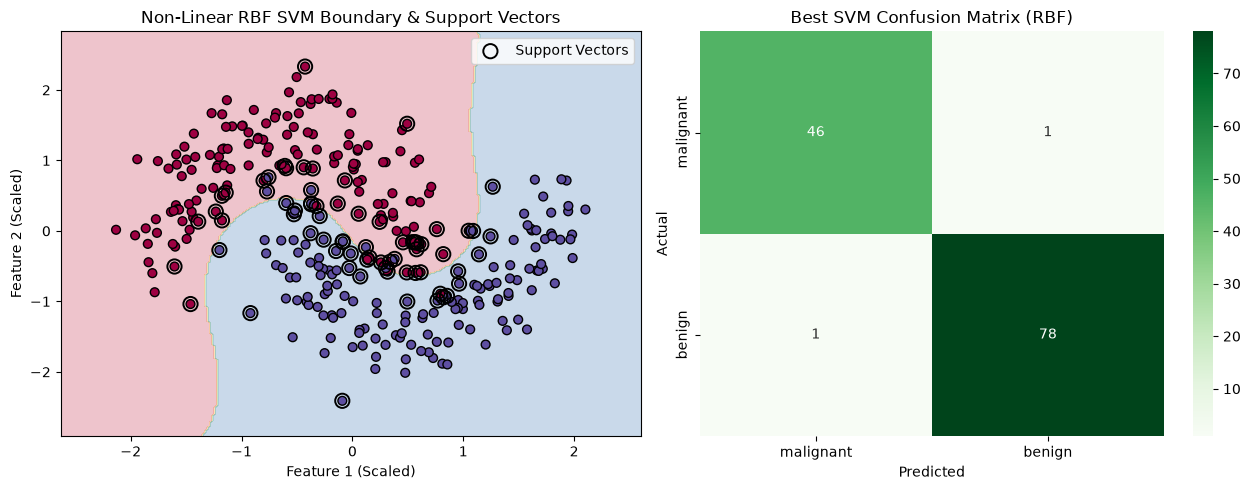

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].contourf(gx, gy, gz, alpha=0.28, cmap="Spectral")
ax[0].scatter(xm_scaled[:, 0], xm_scaled[:, 1], c=ym, cmap="Spectral", edgecolor="black", s=40)
ax[0].scatter(
    moons_rbf.support_vectors_[:, 0],
    moons_rbf.support_vectors_[:, 1],
    s=105,
    facecolors="none",
    edgecolors="black",
    linewidths=1.4,
    label="Support Vectors",
)
ax[0].set_title("Non-Linear RBF SVM Boundary & Support Vectors")
ax[0].set_xlabel("Feature 1 (Scaled)")
ax[0].set_ylabel("Feature 2 (Scaled)")
ax[0].legend()

cmat = confusion_matrix(y_te, best_preds)
sns.heatmap(
    cmat,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names,
    ax=ax[1],
)
ax[1].set_title(f"Best SVM Confusion Matrix ({grid.best_params_['svc__kernel'].upper()})")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

<b>Observation:</b> Cross-validated SVM achieves high holdout accuracy and F1 score, while the RBF kernel captures curved non-linear boundaries using support vectors.